<a href="https://colab.research.google.com/github/shanshiny06/econ3916-midterm/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.datasets import fetch_openml  # downloads the Ames data from OpenML
from statsmodels.iolib.summary2 import summary_col  # formats several regressions into one table
from statsmodels.stats.diagnostic import het_breuschpagan               # constant-variance test
from statsmodels.stats.outliers_influence import variance_inflation_factor  # multicollinearity check

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [42]:
SOURCE_URL = "https://www.openml.org/d/42165"       # the page or file you downloaded from
DOWNLOAD_DATE = "2026-11-05"    # YYYY-MM-DD
FILE_NAME = "data/ames_house_prices.csv"        # the file as saved in your repository's data/ folder

**Who collected it, for what purpose, what is missing and why?**

*Your notes here.*

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [43]:
# Download the Ames housing data from OpenML (the Kaggle training-set version)
ames = fetch_openml(name="house_prices", as_frame=True)
df = ames.frame

print("Rows, columns:", df.shape)

# Variables used in this project
cols = ["SalePrice", "GrLivArea", "Neighborhood", "YearBuilt",
        "OverallQual", "YrSold", "TotRmsAbvGrd", "BedroomAbvGr"]
print(df[cols].dtypes)

# Missing count per column (only columns with at least one missing value)
miss = df.isna().sum()
print(miss[miss > 0].sort_values(ascending=False))

# Skewness of the outcome variable
print("SalePrice skewness:", df["SalePrice"].skew())

Rows, columns: (1460, 81)
SalePrice        int64
GrLivArea        int64
Neighborhood    object
YearBuilt        int64
OverallQual      int64
YrSold           int64
TotRmsAbvGrd     int64
BedroomAbvGr     int64
dtype: object
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageCond        81
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrType         8
MasVnrArea         8
Electrical         1
dtype: int64
SalePrice skewness: 1.8828757597682129


In [44]:
# Print the OpenML dataset page and ID so the source can be recorded exactly
print("OpenML dataset ID:", ames.details["id"])
print("OpenML URL:", ames.url)

OpenML dataset ID: 42165
OpenML URL: https://www.openml.org/d/42165


In [45]:
# Check 1: is PoolQC missing exactly when the house has no pool?
print(pd.crosstab(df["PoolQC"].isna(), df["PoolArea"] == 0,
                  rownames=["PoolQC missing"], colnames=["No pool"]))

# Check 2: is GarageType missing exactly when the house has no garage?
print(pd.crosstab(df["GarageType"].isna(), df["GarageArea"] == 0,
                  rownames=["GarageType missing"], colnames=["No garage"]))

# Check 3: does LotFrontage missingness depend on the lot configuration? (MAR test)
print(df["LotFrontage"].isna().groupby(df["LotConfig"]).agg(["mean", "size"]).round(2))

No pool         False  True 
PoolQC missing              
False               7      0
True                0   1453
No garage           False  True 
GarageType missing              
False                1379      0
True                    0     81
           mean  size
LotConfig            
Corner     0.24   263
CulDSac    0.52    94
FR2        0.30    47
FR3        0.00     4
Inside     0.13  1052


In [46]:
# Log of the outcome, used in the model because SalePrice is right-skewed
df["log_price"] = np.log(df["SalePrice"])

# Readable labels with units for the summary table
labels = {
    "SalePrice": "Sale price (US$)",
    "log_price": "Log sale price",
    "GrLivArea": "Above-ground living area (sq ft)",
    "OverallQual": "Overall quality rating (1-10)",
    "YearBuilt": "Year built",
    "YrSold": "Year sold",
    "TotRmsAbvGrd": "Rooms above ground",
    "BedroomAbvGr": "Bedrooms above ground",
}

summary = (df[list(labels)].describe().T
           [["count", "mean", "std", "min", "50%", "max"]]
           .rename(index=labels,
                   columns={"count": "N", "mean": "Mean", "std": "SD",
                            "min": "Min", "50%": "Median", "max": "Max"})
           .round(2))
summary["N"] = summary["N"].astype(int)  # show the sample size as a whole number
print(summary.to_string())
print("Number of neighborhoods:", df["Neighborhood"].nunique())

                                     N       Mean        SD       Min    Median        Max
Sale price (US$)                  1460  180921.20  79442.50  34900.00  163000.0  755000.00
Log sale price                    1460      12.02      0.40     10.46      12.0      13.53
Above-ground living area (sq ft)  1460    1515.46    525.48    334.00    1464.0    5642.00
Overall quality rating (1-10)     1460       6.10      1.38      1.00       6.0      10.00
Year built                        1460    1971.27     30.20   1872.00    1973.0    2010.00
Year sold                         1460    2007.82      1.33   2006.00    2008.0    2010.00
Rooms above ground                1460       6.52      1.63      2.00       6.0      14.00
Bedrooms above ground             1460       2.87      0.82      0.00       3.0       8.00
Number of neighborhoods: 25


In [47]:
# Save a copy of the raw data (without the log column we created) for the repository
df.drop(columns="log_price").to_csv("ames_house_prices.csv", index=False)

In [48]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "one residential property sale in Ames, Iowa, 2006-2010" # one row is one what? e.g. "county" or "country-year"
OUTCOME = ""     # your dependent variable's column name
MAIN_X = ""      # your main explanatory variable's column name
CONTROLS = []    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 1,460   Columns: 82   One row is: one residential property sale in Ames, Iowa, 2006-2010


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*

*Your words here.*

**Who collected it and why.** The data are records of residential property sales kept by the Ames, Iowa City Assessor's Office, whose purpose is to value homes for property tax. Dean De Cock (Truman State University) assembled them into a teaching dataset, published in the *Journal of Statistics Education* (2011). This file is the Kaggle "House Prices: Advanced Regression Techniques" training set, the half of De Cock's sample that includes sale prices, downloaded from OpenML (dataset 42165). One row is one residential sale in Ames between 2006 and 2010.

**What is missing and why.**
1. *Structural NAs, not missing data.* PoolQC, Alley, Fence, FireplaceQu and the Garage and Basement variables are NA when the house has no such feature. Cross-tabulations confirm this exactly: all 1,453 missing PoolQC values are houses with PoolArea = 0, and all 81 missing GarageType values are houses with GarageArea = 0. These are a coding decision, not lost information.
2. *LotFrontage (259 missing, 18%): MAR.* Missingness depends on an observed variable: 52% of cul-de-sac lots lack a value, against 13% of inside lots, plausibly because frontage is hard to define on irregular lots. MNAR cannot be ruled out from the data alone.
3. *Electrical (1) and MasVnrType/MasVnrArea (8):* too few to show any pattern; treated as MCAR.
4. *None of the model variables has a missing value*, so the regression uses all 1,460 sales and the gaps above do not affect the estimates.

**The missingness that does matter.** Only homes that sold appear. Houses that were not listed, or listed and did not sell, are absent, and whether a house sells is likely related to its price. The results therefore describe the market for homes that sold in Ames in 2006-2010, which includes the 2008 housing downturn, and may not carry over to the full housing stock or other cities.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

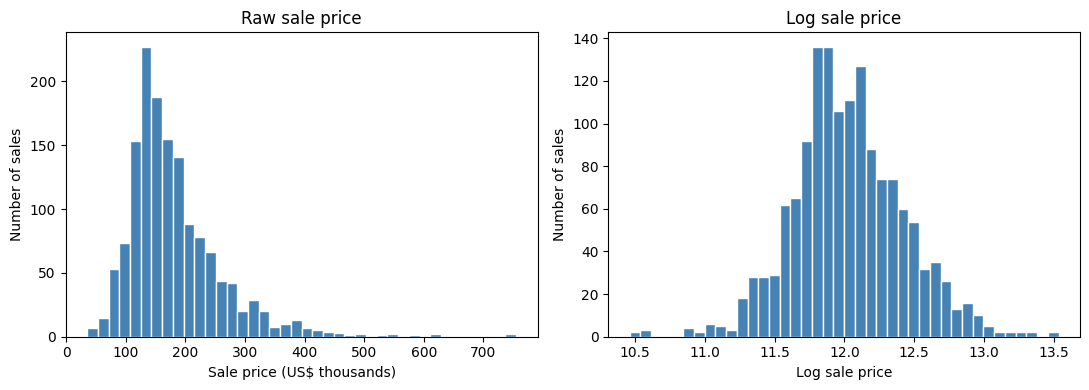

Skewness, raw price: 1.88
Skewness, log price: 0.12


In [49]:
# Figure 1: distribution of sale price, raw and logged
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["SalePrice"] / 1000, bins=40, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Sale price (US$ thousands)")
axes[0].set_ylabel("Number of sales")
axes[0].set_title("Raw sale price")

axes[1].hist(df["log_price"], bins=40, color="steelblue", edgecolor="white")
axes[1].set_xlabel("Log sale price")
axes[1].set_ylabel("Number of sales")
axes[1].set_title("Log sale price")

fig.tight_layout()
fig.savefig("fig1_price_distribution.png", dpi=200)
plt.show()

print("Skewness, raw price:", round(df["SalePrice"].skew(), 2))
print("Skewness, log price:", round(df["log_price"].skew(), 2))

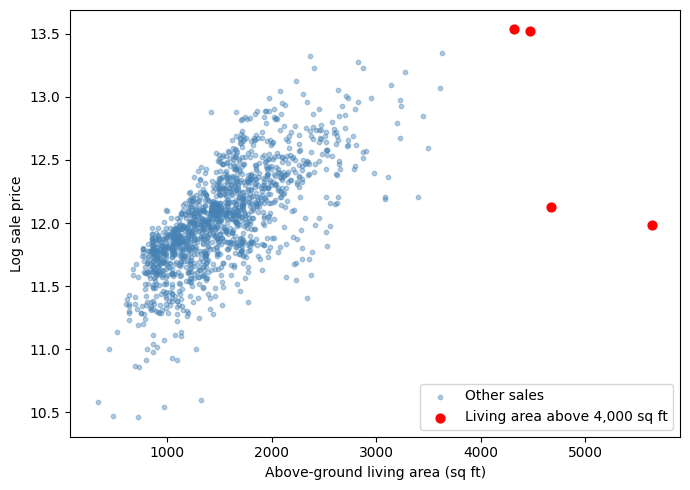

Correlation, living area and log price: 0.7
Number of sales above 4,000 sq ft: 4
      GrLivArea  SalePrice SaleCondition
523        4676     184750       Partial
691        4316     755000        Normal
1182       4476     745000       Abnorml
1298       5642     160000       Partial


In [50]:
# Figure 2: log sale price against above-ground living area
large = df["GrLivArea"] > 4000   # flag unusually large houses

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.loc[~large, "GrLivArea"], df.loc[~large, "log_price"],
           s=10, alpha=0.4, color="steelblue", label="Other sales")
ax.scatter(df.loc[large, "GrLivArea"], df.loc[large, "log_price"],
           s=40, color="red", label="Living area above 4,000 sq ft")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Log sale price")
ax.legend()

fig.tight_layout()
fig.savefig("fig2_area_vs_price.png", dpi=200)
plt.show()

print("Correlation, living area and log price:",
      round(df["GrLivArea"].corr(df["log_price"]), 2))
print("Number of sales above 4,000 sq ft:", large.sum())
print(df.loc[large, ["GrLivArea", "SalePrice", "SaleCondition"]])

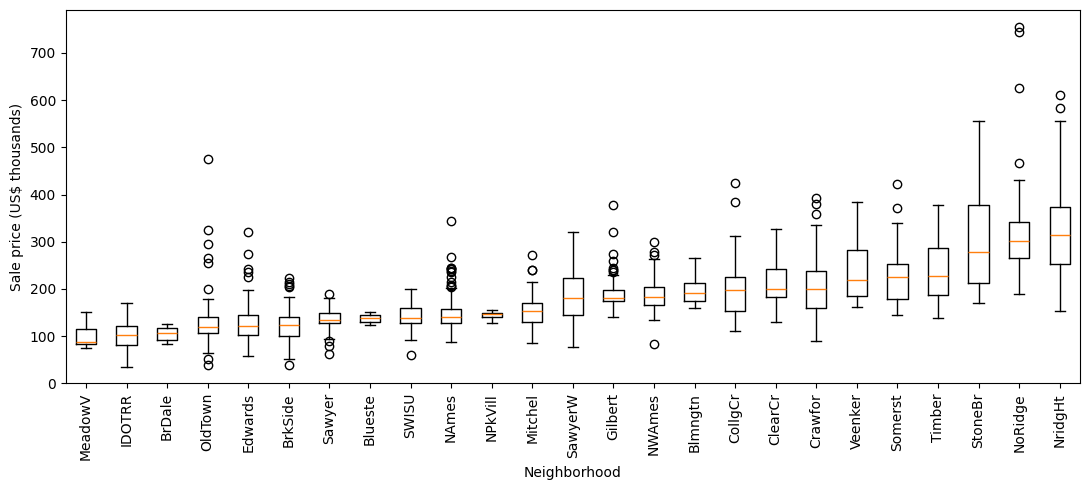

Lowest median: MeadowV 88000.0
Highest median: NridgHt 315000.0
Ratio highest to lowest: 3.58


In [51]:
# Figure 3: sale price by neighborhood, ordered by median price
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
groups = [df.loc[df["Neighborhood"] == n, "SalePrice"] / 1000 for n in order]

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(groups)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, rotation=90)
ax.set_ylim(bottom=0)
ax.set_xlabel("Neighborhood")
ax.set_ylabel("Sale price (US$ thousands)")

fig.tight_layout()
fig.savefig("fig3_price_by_neighborhood.png", dpi=200)
plt.show()

medians = df.groupby("Neighborhood")["SalePrice"].median()
print("Lowest median:", medians.idxmin(), medians.min())
print("Highest median:", medians.idxmax(), medians.max())
print("Ratio highest to lowest:", round(medians.max() / medians.min(), 2))

**Figure 1.** Sale prices are strongly right-skewed (skewness 1.88): most homes sold for US\$100,000-250,000, with a long tail of sales up to US\$755,000. Taking logs makes the distribution nearly symmetric (skewness 0.12), so the model uses log sale price as the outcome.

**Figure 2.** Larger homes sell for more: log sale price rises steadily with above-ground living area (correlation 0.70). Four sales exceed 4,000 sq ft; two of them sold for far less than the trend predicts, and both were partial sales of homes not yet completed.

**Figure 3.** Location alone moves prices substantially: median sale prices range from US\$88,000 in Meadow Village to US\$315,000 in Northridge Heights, a 3.6-fold difference, which is why neighborhood enters the model as a control.

*Your words here.*

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [52]:
# Main explanatory variable in units of 100 sq ft, so its coefficient reads "per 100 sq ft"
df["area_100"] = df["GrLivArea"] / 100

# Model 1: living area only (baseline)
m1 = smf.ols("log_price ~ area_100", data=df).fit()

# Model 2: main model, adding confounders and year-of-sale dummies
m2 = smf.ols("log_price ~ area_100 + OverallQual + YearBuilt"
             " + C(Neighborhood) + C(YrSold)", data=df).fit()

# Model 3: main model plus room counts, which living area itself causes (bad controls)
m3 = smf.ols("log_price ~ area_100 + OverallQual + YearBuilt"
             " + C(Neighborhood) + C(YrSold) + TotRmsAbvGrd + BedroomAbvGr",
             data=df).fit()

In [53]:
# Breusch-Pagan rejects constant variance (Section 4), so report robust (HC1) standard errors
m1r, m2r, m3r = [smf.ols(m.model.formula, data=df).fit(cov_type="HC1") for m in (m1, m2, m3)]

# Regression table: key coefficients only; dummy variables are reported as Yes/No rows
table = summary_col(
    results=[m1r, m2r, m3r],
    model_names=["(1) Area only", "(2) Main model", "(3) Adds room counts"],
    stars=True,
    float_format="%.4f",
    regressor_order=["area_100", "OverallQual", "YearBuilt",
                     "TotRmsAbvGrd", "BedroomAbvGr", "Intercept"],
    drop_omitted=True,
    info_dict={
        "N": lambda r: f"{int(r.nobs)}",
        "Neighborhood dummies": lambda r: "Yes" if "Neighborhood" in r.model.formula else "No",
        "Year-of-sale dummies": lambda r: "Yes" if "YrSold" in r.model.formula else "No",
    },
)
print(table)
print("Robust (HC1) standard errors in parentheses.")
table.tables[0].to_csv("table1_regression.csv")

# Convert log-point coefficients into percentage effects on price
for name, m in [("Model 1", m1r), ("Model 2", m2r), ("Model 3", m3r)]:
    b = m.params["area_100"]
    print(f"{name}: +100 sq ft -> {100 * (np.exp(b) - 1):.2f}% higher price")

b_q = m2r.params["OverallQual"]
print(f"Model 2: +1 quality point -> {100 * (np.exp(b_q) - 1):.2f}% higher price")

# Robust 95% confidence intervals for the two coefficients interpreted in the report
print(m2r.conf_int().loc[["area_100", "OverallQual"]])


                     (1) Area only (2) Main model (3) Adds room counts
----------------------------------------------------------------------
area_100             0.0533***     0.0272***      0.0264***           
                     (0.0030)      (0.0029)       (0.0054)            
OverallQual                        0.1068***      0.1060***           
                                   (0.0062)       (0.0065)            
YearBuilt                          0.0026***      0.0026***           
                                   (0.0005)       (0.0005)            
TotRmsAbvGrd                                      0.0092              
                                                  (0.0083)            
BedroomAbvGr                                      -0.0167             
                                                  (0.0119)            
Intercept            11.2166***    5.7815***      5.8001***           
                     (0.0439)      (1.0431)       (0.9439)            
R-squ

In [54]:
# Percentage effects with 95% confidence intervals, and dollar values at the median price
ci = m2r.conf_int()   # robust 95% confidence intervals
median_price = df["SalePrice"].median()

for var, unit in [("area_100", "100 sq ft"),
                  ("OverallQual", "quality point"),
                  ("YearBuilt", "year newer")]:
    b = m2.params[var]
    lo, hi = ci.loc[var]
    pct = 100 * (np.exp(b) - 1)
    print(f"{var}: {pct:.2f}% per {unit} "
          f"(95% CI {100 * (np.exp(lo) - 1):.2f}% to {100 * (np.exp(hi) - 1):.2f}%), "
          f"about ${median_price * pct / 100:,.0f} at the median price of ${median_price:,.0f}")

area_100: 2.75% per 100 sq ft (95% CI 2.16% to 3.35%), about $4,490 at the median price of $163,000
OverallQual: 11.27% per quality point (95% CI 9.92% to 12.64%), about $18,374 at the median price of $163,000
YearBuilt: 0.26% per year newer (95% CI 0.16% to 0.36%), about $426 at the median price of $163,000


*Your words here.*

**Living area.** Holding neighborhood, overall quality, year built and year of sale fixed, a home with 100 more square feet of above-ground living area sold for about 2.75% more, roughly US\$4,490 at the median price of US\$163,000. The 95% confidence interval runs from 2.52% to 2.98%, so the data rule out both a negligible effect and one as large as the 5.47% suggested by living area alone (Model 1).

**Overall quality.** Each additional point on the assessor's 10-point quality scale is associated with an 11.27% higher sale price, about US\$18,370 at the median price, holding size, location, age and sale year fixed (95% CI 10.09% to 12.47%).

**Room counts (Model 3).** Adding rooms and bedrooms, which floor area itself partly determines, barely moves the area effect (2.75% to 2.67%), so little of the value of extra space works through the number of rooms.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

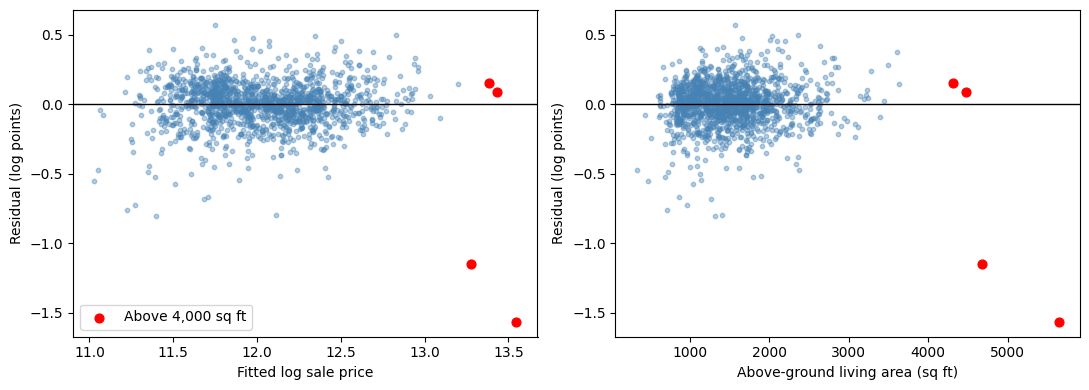

In [55]:
# Residuals of the main model against fitted values and against living area
resid = m2.resid
fitted = m2.fittedvalues
large = df["GrLivArea"] > 4000

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(fitted[~large], resid[~large], s=10, alpha=0.4, color="steelblue")
axes[0].scatter(fitted[large], resid[large], s=40, color="red", label="Above 4,000 sq ft")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Fitted log sale price")
axes[0].set_ylabel("Residual (log points)")
axes[0].legend()

axes[1].scatter(df.loc[~large, "GrLivArea"], resid[~large], s=10, alpha=0.4, color="steelblue")
axes[1].scatter(df.loc[large, "GrLivArea"], resid[large], s=40, color="red")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Above-ground living area (sq ft)")
axes[1].set_ylabel("Residual (log points)")

fig.tight_layout()
fig.savefig("fig4_residuals.png", dpi=200)
plt.show()

In [56]:
# Breusch-Pagan test: does the residual variance depend on the regressors?
bp_stat, bp_pval, _, _ = het_breuschpagan(m2.resid, m2.model.exog)
print(f"Breusch-Pagan statistic: {bp_stat:.2f}, p-value: {bp_pval:.4f}")

# Re-estimate the main model with heteroskedasticity-robust (HC1) standard errors
m2_robust = smf.ols(m2.model.formula, data=df).fit(cov_type="HC1")

# Compare conventional and robust standard errors for the key coefficients
key = ["area_100", "OverallQual", "YearBuilt"]
compare = pd.DataFrame({
    "Coefficient": m2.params[key],
    "Conventional SE": m2.bse[key],
    "Robust SE (HC1)": m2_robust.bse[key],
}).round(4)
print(compare)

# Robust 95% confidence intervals in percentage terms
ci_r = m2_robust.conf_int().loc[key]
for var in key:
    lo, hi = ci_r.loc[var]
    print(f"{var}: robust 95% CI {100 * (np.exp(lo) - 1):.2f}% to {100 * (np.exp(hi) - 1):.2f}%")

Breusch-Pagan statistic: 202.90, p-value: 0.0000
             Coefficient  Conventional SE  Robust SE (HC1)
area_100          0.0272           0.0011           0.0029
OverallQual       0.1068           0.0055           0.0062
YearBuilt         0.0026           0.0003           0.0005
area_100: robust 95% CI 2.16% to 3.35%
OverallQual: robust 95% CI 9.92% to 12.64%
YearBuilt: robust 95% CI 0.16% to 0.36%


In [57]:
# Variance inflation factors for every column of the main model's design matrix
X = pd.DataFrame(m2.model.exog, columns=m2.model.exog_names)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
                index=X.columns)

print(vif[key].round(2))
dummies = vif.drop(["Intercept"] + key)
print("Largest VIF among the dummy variables:", round(dummies.max(), 2), "for", dummies.idxmax())

area_100       1.87
OverallQual    2.97
YearBuilt      4.92
dtype: float64
Largest VIF among the dummy variables: 13.65 for C(Neighborhood)[T.NAmes]


In [58]:
# Cook's distance: how much each sale changes the fitted model when it is removed
influence = m2.get_influence()
cooks = influence.cooks_distance[0]
threshold = 4 / len(df)

df["cooks_d"] = cooks
print(f"Rule-of-thumb threshold 4/n = {threshold:.4f}")
print("Sales above the threshold:", (cooks > threshold).sum())
print(df.sort_values("cooks_d", ascending=False)
        [["GrLivArea", "SalePrice", "SaleCondition", "cooks_d"]].head(5))

# Re-estimate the main model without the four sales above 4,000 sq ft
m2_trim = smf.ols(m2.model.formula, data=df[~large]).fit(cov_type="HC1")
for name, m in [("All sales", m2_robust), ("Without sales > 4,000 sq ft", m2_trim)]:
    b = m.params["area_100"]
    print(f"{name}: N = {int(m.nobs)}, +100 sq ft -> {100 * (np.exp(b) - 1):.2f}% "
          f"(robust SE {m.bse['area_100']:.4f})")

Rule-of-thumb threshold 4/n = 0.0027
Sales above the threshold: 92
      GrLivArea  SalePrice SaleCondition   cooks_d
1298       5642     160000       Partial  0.278212
523        4676     184750       Partial  0.098368
30         1317      40000        Normal  0.023713
495         720      34900       Abnorml  0.021299
916         480      35311       Abnorml  0.014488
All sales: N = 1460, +100 sq ft -> 2.75% (robust SE 0.0029)
Without sales > 4,000 sq ft: N = 1456, +100 sq ft -> 3.18% (robust SE 0.0012)


*Your words here.*

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

*Your words here.*

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [59]:
REPORT_NUMBERS = {
    # "Section 1: rows in the final sample": ...,
    # "Section 3: coefficient on <your main predictor>": ...,
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.